In [6]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
# Load the preprocessed dataset
with open('./data/preprocessed/Preprocessed_data.pkl', 'rb') as f:
    data = pickle.load(f)

# Extract Madrid (source city)
X_madrid = data['X_madrid']
y_madrid = data['y_madrid']

# Extract Amsterdam (target city)
X_amsterdam = data['X_amsterdam']
y_amsterdam = data['y_amsterdam']

# Extract pixel IDs
pixel_ids_madrid = data['pixel_ids_madrid']
pixel_ids_amsterdam = data['pixel_ids_amsterdam']

# Extract feature names
feature_names = data['feature_names']

print("Preprocessed data loaded successfully!")

Preprocessed data loaded successfully!


XGBoost version: 3.4.1
Madrid NaN: 0
Madrid infinite: 0
Amsterdam NaN: 0
Amsterdam infinite: 0
Madrid shape: (76263, 92)
Amsterdam shape: (25992, 92)
Madrid classes: [1 2 3 4]
Amsterdam classes: [1 2 3 4]
Training XGBoost using 5-fold CV
Fold 1/5 | Macro F1: 0.6217 | Accuracy: 0.6222 | Balanced Accuracy: 0.6279
Fold 2/5 | Macro F1: 0.6272 | Accuracy: 0.6269 | Balanced Accuracy: 0.6326
Fold 3/5 | Macro F1: 0.6247 | Accuracy: 0.6256 | Balanced Accuracy: 0.6298
Fold 4/5 | Macro F1: 0.6149 | Accuracy: 0.6147 | Balanced Accuracy: 0.6215
Fold 5/5 | Macro F1: 0.6096 | Accuracy: 0.6100 | Balanced Accuracy: 0.6154

FINAL CROSS-VALIDATION RESULTS
Macro F1: 0.6196 +/- 0.0065
Accuracy: 0.6199 +/- 0.0065
Balanced Accuracy: 0.6254 +/- 0.0062
              precision    recall  f1-score   support

     Class 1     0.5096    0.6106    0.5555     13794
     Class 2     0.6447    0.5837    0.6127     27152
     Class 3     0.6166    0.6122    0.6144     18672
     Class 4     0.6965    0.6953    0.6959  

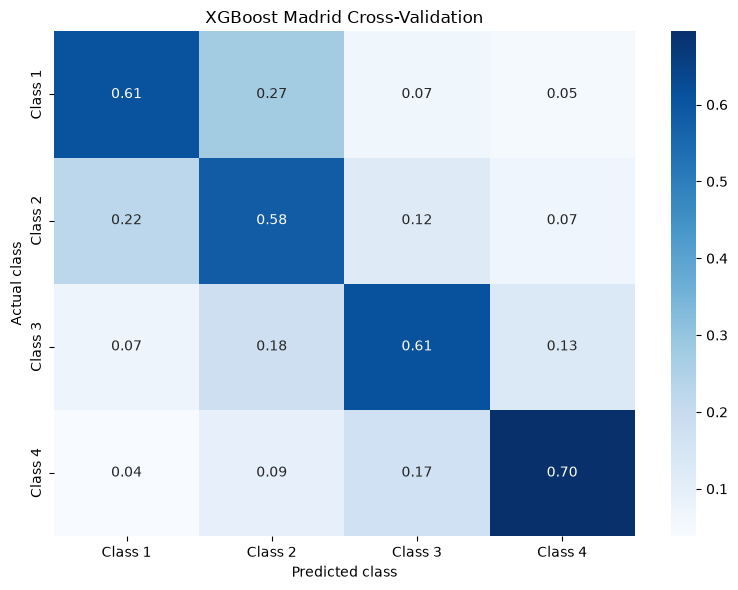

Training final XGBoost model...
Final XGBoost model trained successfully!
Training accuracy: 0.6535279231081914


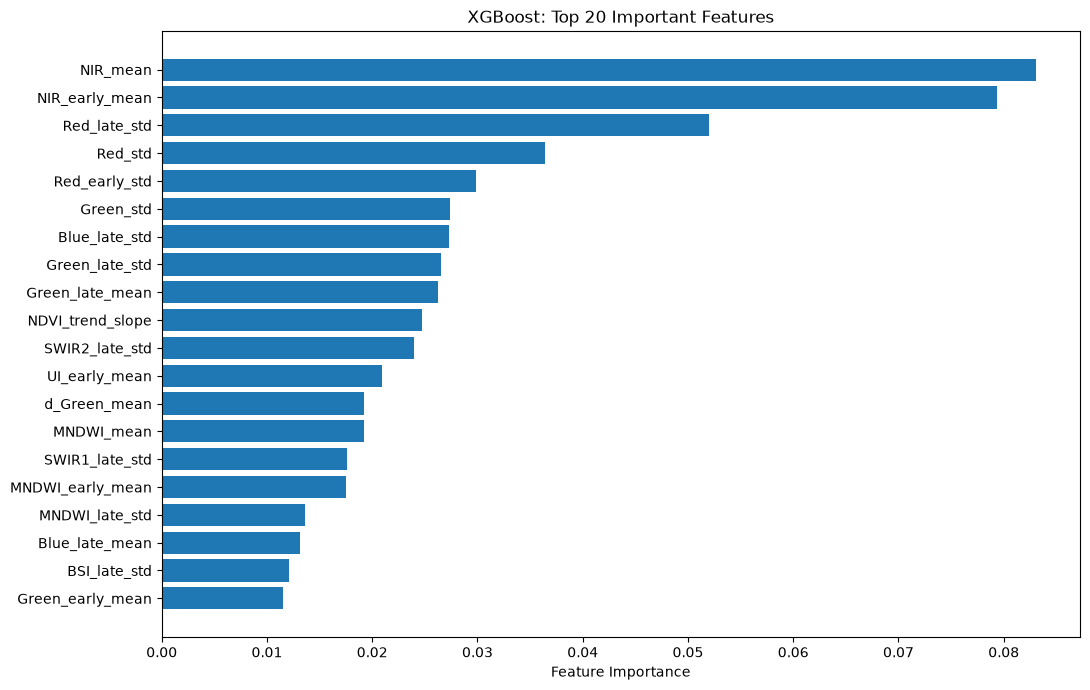

TOP 10 FEATURES
1. NIR_mean: 0.08309
2. NIR_early_mean: 0.07934
3. Red_late_std: 0.05199
4. Red_std: 0.03645
5. Red_early_std: 0.02986
6. Green_std: 0.02739
7. Blue_late_std: 0.02729
8. Green_late_std: 0.02658
9. Green_late_mean: 0.02625
10. NDVI_trend_slope: 0.02473
Amsterdam predictions completed!
Predicted class distribution: 1    14548
2     4548
3     3241
4     3655
Name: count, dtype: int64


In [7]:

import xgboost as xgb

from xgboost import XGBClassifier

from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score
)

from sklearn.utils.class_weight import compute_sample_weight

print("XGBoost version:", xgb.__version__)
# Convert features to numerical arrays
#load data

X_madrid = np.asarray(X_madrid, dtype=np.float32)
X_amsterdam = np.asarray(X_amsterdam, dtype=np.float32)

y_madrid = np.asarray(y_madrid, dtype=int)
y_amsterdam = np.asarray(y_amsterdam, dtype=int)

# Check for missing or infinite values
print("Madrid NaN:", np.isnan(X_madrid).sum())
print("Madrid infinite:", np.isinf(X_madrid).sum())

print("Amsterdam NaN:", np.isnan(X_amsterdam).sum())
print("Amsterdam infinite:", np.isinf(X_amsterdam).sum())

print("Madrid shape:", X_madrid.shape)
print("Amsterdam shape:", X_amsterdam.shape)

print("Madrid classes:", np.unique(y_madrid))
print("Amsterdam classes:", np.unique(y_amsterdam))
XGB_PARAMS = {
    "objective": "multi:softprob",
    "num_class": 4,
    "n_estimators": 600,
    "learning_rate": 0.03,
    "max_depth": 4,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 5,
    "gamma": 0.1,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": 42,
    "n_jobs": -1
}
#Train XGBoost
# Encode classes as 0, 1, 2, 3 for XGBoost
classes = np.sort(np.unique(y_madrid))

class_to_int = {c: i for i, c in enumerate(classes)}
int_to_class = {i: c for c, i in class_to_int.items()}

y_madrid_enc = np.array([
    class_to_int[y] for y in y_madrid
])

# Cross-validation configuration
N_FOLDS = 5
N_REPEATS = 1

cv = RepeatedStratifiedKFold(
    n_splits=N_FOLDS,
    n_repeats=N_REPEATS,
    random_state=42
)

all_f1 = []
all_accuracy = []
all_balanced_accuracy = []

oof_true = []
oof_pred = []
oof_proba = []
oof_indices = []

print("Training XGBoost using 5-fold CV")
print("=" * 55)

for fold, (tr_idx, val_idx) in enumerate(
    cv.split(X_madrid, y_madrid_enc), 1
):

    X_tr = X_madrid[tr_idx]
    X_val = X_madrid[val_idx]

    y_tr = y_madrid_enc[tr_idx]
    y_val = y_madrid_enc[val_idx]

    # Calculate class weights using training data only
    weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = XGBClassifier(**XGB_PARAMS)

    model.fit(
        X_tr,
        y_tr,
        sample_weight=weights,
        verbose=False
    )

    # Predictions
    pred_enc = model.predict(X_val).astype(int)
    proba = model.predict_proba(X_val)

    # Convert predictions back to original labels
    pred = np.array([
        int_to_class[i] for i in pred_enc
    ])

    # Store results
    oof_true.extend(y_madrid[val_idx])
    oof_pred.extend(pred)
    oof_proba.extend(proba)
    oof_indices.extend(val_idx)

    # Evaluation
    fold_f1 = f1_score(
        y_madrid[val_idx],
        pred,
        average="macro"
    )

    fold_acc = accuracy_score(
        y_madrid[val_idx],
        pred
    )

    fold_bal_acc = balanced_accuracy_score(
        y_madrid[val_idx],
        pred
    )

    all_f1.append(fold_f1)
    all_accuracy.append(fold_acc)
    all_balanced_accuracy.append(fold_bal_acc)

    print(
        f"Fold {fold}/{N_FOLDS} | "
        f"Macro F1: {fold_f1:.4f} | "
        f"Accuracy: {fold_acc:.4f} | "
        f"Balanced Accuracy: {fold_bal_acc:.4f}"
    )

# Convert results into arrays
oof_true = np.array(oof_true)
oof_pred = np.array(oof_pred)
oof_proba = np.array(oof_proba)
oof_indices = np.array(oof_indices)

print("\nFINAL CROSS-VALIDATION RESULTS")
print("=" * 55)

print(
    f"Macro F1: {np.mean(all_f1):.4f} "
    f"+/- {np.std(all_f1):.4f}"
)

print(
    f"Accuracy: {np.mean(all_accuracy):.4f} "
    f"+/- {np.std(all_accuracy):.4f}"
)

print(
    f"Balanced Accuracy: {np.mean(all_balanced_accuracy):.4f} "
    f"+/- {np.std(all_balanced_accuracy):.4f}"
)
print(
    classification_report(
        oof_true,
        oof_pred,
        labels=classes,
        target_names=[
            f"Class {c}" for c in classes
        ],
        digits=4,
        zero_division=0
    )
)
#Confusion matrix
import seaborn as sns

cm = confusion_matrix(
    oof_true,
    oof_pred,
    labels=classes,
    normalize="true"
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=[
        f"Class {c}" for c in classes
    ],
    yticklabels=[
        f"Class {c}" for c in classes
    ]
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("XGBoost Madrid Cross-Validation")
plt.tight_layout()
plt.show()
#Training xgboost in madrid data
print("Training final XGBoost model...")

final_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_madrid_enc
)

xgb_final = XGBClassifier(**XGB_PARAMS)

xgb_final.fit(
    X_madrid,
    y_madrid_enc,
    sample_weight=final_weights,
    verbose=False
)

print("Final XGBoost model trained successfully!")
#training performance
train_pred_enc = xgb_final.predict(X_madrid).astype(int)

train_pred = np.array([
    int_to_class[i] for i in train_pred_enc
])

print(
    "Training accuracy:",
    accuracy_score(y_madrid, train_pred)
)
# nvestigate feature importance
# This helps us understand which Landsat features contribute most to building age classification.
importances = xgb_final.feature_importances_

sorted_idx = np.argsort(importances)[::-1]

TOP_N = 20

plt.figure(figsize=(11, 7))

plt.barh(
    range(TOP_N),
    importances[sorted_idx[:TOP_N]][::-1]
)

plt.yticks(
    range(TOP_N),
    [feature_names[i] for i in sorted_idx[:TOP_N]][::-1]
)

plt.xlabel("Feature Importance")
plt.title("XGBoost: Top 20 Important Features")

plt.tight_layout()
plt.show()

print("TOP 10 FEATURES")

for rank, idx in enumerate(sorted_idx[:10]):
    print(
        f"{rank+1}. {feature_names[idx]}: "
        f"{importances[idx]:.5f}"
    )
# Predict Amsterdam classes
#Use the Madrid-trained model to predict Amsterdam
ams_pred_enc = xgb_final.predict(
    X_amsterdam
).astype(int)

y_ams_pred_xgb = np.array([
    int_to_class[i] for i in ams_pred_enc
])

# Prediction probabilities
proba_amsterdam_xgb = xgb_final.predict_proba(
    X_amsterdam
)

print("Amsterdam predictions completed!")

print(
    "Predicted class distribution:",
    pd.Series(y_ams_pred_xgb).value_counts().sort_index()
)